# Fine-Grained Bird Classification on CUB-200-2011 (25 classes)
## CNN architecture ablations and a custom parameter-efficient network

# 1. Importing Libraries

In [ ]:

import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import os 

print(f'PyTorch version : {torch.__version__}')
print(f'CUDA version    : {torch.version.cuda}')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device          : {device}')

PyTorch version : 2.12.0
CUDA version    : None
Device          : cpu


# 2. Global Settings

In [3]:
def START_seed():
    seed = 66
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


NUM_CLASSES = 25
MAX_PARAMS = 500_000
EPOCHS = 50
IMG_SIZE = 128  # all images are resized to IMG_SIZE x IMG_SIZE

START_seed()

# 3. Dataset

## 3.1 Dataset Class

The data you received is organised as follows:
```
data/
└── train_imgs/
    ├── 001.Black_footed_Albatross/
    ├── 002.Laysan_Albatross/
    └── ...  (25 class folders, 001–025)
```

- Only `train_imgs/` is provided. The dataset class splits it into **train** and **validation** sets automatically.
- The **test set** is held out for testing.



In [4]:
class CUB25Dataset(Dataset):
    """
    Loads the 25-class CUB subset from train_imgs/.

    Args:
        root         : path to the data directory (must contain train_imgs/)
        split        : 'train' | 'val'
                       Both are carved from train_imgs/ using a fixed seed.
        transform    : torchvision transform pipeline
        val_fraction : fraction of train_imgs/ reserved for validation (default 0.2)
    """

    def __init__(self, root, split='train', transform=None, val_fraction=0.2):
        super().__init__()
        assert split in ('train', 'val'), f"split must be 'train' or 'val', got '{split}'"
        self.transform = transform

        img_dir = os.path.join(root, 'train_imgs')

        # Discover classes: sorted folder names -> label 0..24
        class_names = sorted([
            d for d in os.listdir(img_dir)
            if os.path.isdir(os.path.join(img_dir, d))
        ])
        # Keep only the first 25 classes (001–025)
        class_names = class_names[:NUM_CLASSES]
        assert len(class_names) == NUM_CLASSES, (
            f'Expected {NUM_CLASSES} class folders, found {len(class_names)}.'
        )
        self.class_to_idx = {name: idx for idx, name in enumerate(class_names)}

        # Collect all (image_path, label) pairs
        all_samples = []
        for cls_name in class_names:
            cls_dir = os.path.join(img_dir, cls_name)
            label = self.class_to_idx[cls_name]
            for fname in sorted(os.listdir(cls_dir)):
                if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    all_samples.append((os.path.join(cls_dir, fname), label))

        # Reproducible stratified train/val split
        rng = np.random.RandomState(66)
        train_samples, val_samples = [], []
        for cls_name in class_names:
            cls_samples = [s for s in all_samples if s[1] == self.class_to_idx[cls_name]]
            cls_samples = sorted(cls_samples)  # deterministic order
            idx = np.arange(len(cls_samples))
            rng.shuffle(idx)
            n_val = max(1, int(len(cls_samples) * val_fraction))
            val_samples += [cls_samples[i] for i in idx[:n_val]]
            train_samples += [cls_samples[i] for i in idx[n_val:]]

        self.samples = train_samples if split == 'train' else val_samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


print('CUB25Dataset defined.')


CUB25Dataset defined.


## 3.2 Base Transforms and Data Loaders

In [5]:
# ── Set this to your local data directory ────────────────────────────────────
DATA_ROOT = './data'  # must contain train_imgs/
# ─────────────────────────────────────────────────────────────────────────────

START_seed()

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

base_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

base_val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_batch_size = 64
val_batch_size = 64

NUM_WORKERS = 0

train_set = CUB25Dataset(DATA_ROOT, split='train', transform=base_train_transform)
val_set = CUB25Dataset(DATA_ROOT, split='val', transform=base_val_transform)

train_loader = DataLoader(train_set, batch_size=train_batch_size, shuffle=True,
                          num_workers=NUM_WORKERS)
val_loader = DataLoader(val_set, batch_size=val_batch_size, shuffle=False,
                        num_workers=NUM_WORKERS)

print(f'Train samples : {len(train_set)}')
print(f'Val   samples : {len(val_set)}')
print(f'Classes       : {NUM_CLASSES}')


Train samples : 567
Val   samples : 130
Classes       : 25


## 3.3 Visualising the Data

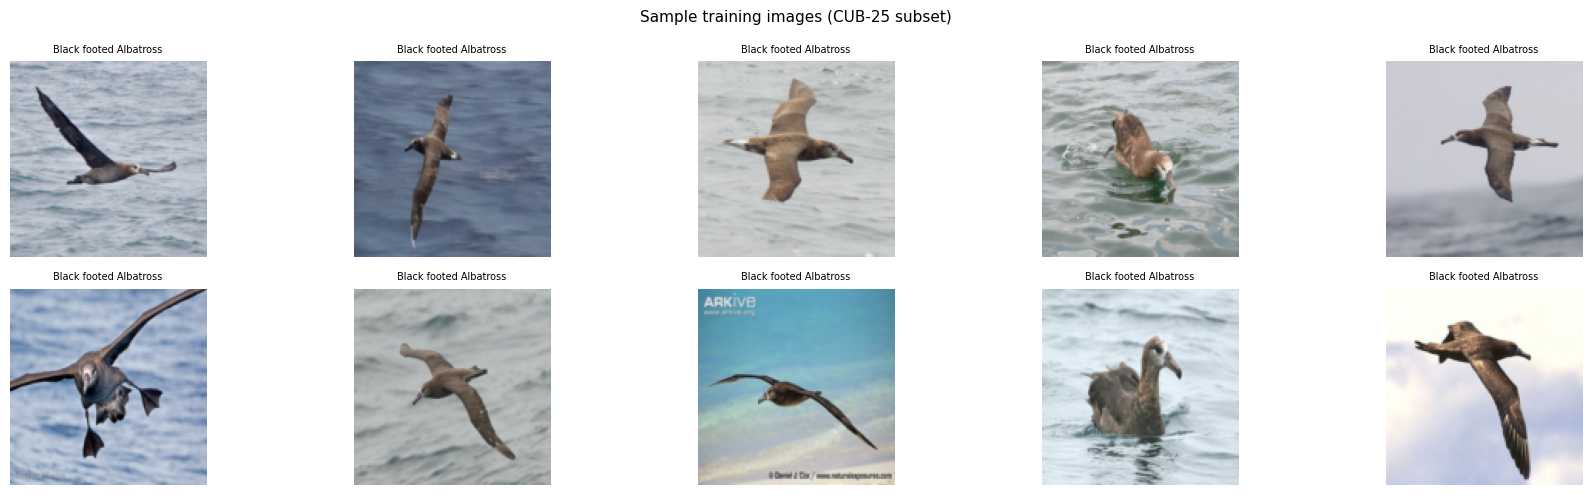

In [72]:
idx_to_class = {v: k for k, v in train_set.class_to_idx.items()}


def denorm(tensor, mean=MEAN, std=STD):
    t = tensor.clone()
    for c, (m, s) in enumerate(zip(mean, std)):
        t[c] = t[c] * s + m
    return t.clamp(0, 1)


plt.figure(figsize=(18, 5))
for i in range(10):
    img, lbl = train_set[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(denorm(img).permute(1, 2, 0).numpy())
    plt.title(idx_to_class[lbl].split('.')[1].replace('_', ' '), fontsize=7)
    plt.axis('off')
plt.suptitle('Sample training images (CUB-25 subset)', fontsize=11)
plt.tight_layout()
plt.show()


# 4. Training & Evaluation Helpers

In [7]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def train_one_epoch(model, device, loader, optimizer, criterion, epoch):
    model.train()
    total_loss = 0.0
    for data, target in loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        loss = criterion(model(data), target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(loader)
    print(f'  [Train] Epoch {epoch:02d}  Loss: {avg_loss:.4f}')
    return avg_loss


def evaluate(model, device, loader, criterion, split_name='Val'):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            total_loss += criterion(output, target).item()
            correct += output.argmax(dim=1).eq(target).sum().item()
    avg_loss = total_loss / len(loader)
    accuracy = 100.0 * correct / len(loader.dataset)
    print(f'  [{split_name}]   Loss: {avg_loss:.4f}  Accuracy: {correct}/{len(loader.dataset)} ({accuracy:.2f}%)')
    return accuracy


def run_experiment(model, train_loader, val_loader,
                   lr=1e-3, optimizer_name='Adam', epochs=EPOCHS, device=device):
    """Train model and return (best_val_acc, train_losses, val_accs)."""
    criterion = nn.CrossEntropyLoss()
    if optimizer_name.upper() == 'ADAM':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    model.to(device)
    train_losses, val_accs = [], []
    best_acc, best_epoch = 0.0, 0

    t0 = time.time()
    for epoch in range(1, epochs + 1):
        loss = train_one_epoch(model, device, train_loader, optimizer, criterion, epoch)
        acc = evaluate(model, device, val_loader, criterion)
        train_losses.append(loss)
        val_accs.append(acc)
        if acc > best_acc:
            best_acc, best_epoch = acc, epoch

    print(f'\nBest val accuracy : {best_acc:.2f}% at epoch {best_epoch}')
    print(f'Total time        : {time.time() - t0:.1f}s')
    print(f'Parameters        : {count_parameters(model):,}')
    return best_acc, train_losses, val_accs


def plot_curves(results_dict, title='Training curves'):
    """results_dict: {label: (train_losses, val_accs)}"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    for label, (losses, accs) in results_dict.items():
        ax1.plot(losses, label=label)
        ax2.plot(accs, label=label)
    ax1.set_title('Train Loss');
    ax1.set_xlabel('Epoch');
    ax1.legend()
    ax2.set_title('Val Accuracy (%)');
    ax2.set_xlabel('Epoch');
    ax2.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


print('Helpers defined.')

Helpers defined.


# 5. Task 0 — Baseline Architecture

This is the **base LeNet-style network** adapted for CUB-25 (input `128×128`, 25 output classes).  
All Tasks 1–4 modify this baseline independently — do **not** carry changes between tasks.

In [8]:
class LeNetBase(nn.Module):
    """
    Baseline network for CUB-25.
    Input : (B, 3, 128, 128)
    Flow  : Conv(3->32,  k=3) -> BN -> ReLU -> MaxPool(2)   # 128->126->63
            Conv(32->64, k=3) -> BN -> ReLU -> MaxPool(2)   #  63-> 61->30
            Conv(64->128,k=3) -> BN -> ReLU -> MaxPool(2)   #  30-> 28->14
            AdaptiveAvgPool(4x4)                             #  14->  4
            Flatten -> FC(128*4*4->128) -> ReLU
                    -> FC(128->64)       -> ReLU
                    -> FC(64->25)
    Parameters: ~368k
    """

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2)
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2)
        x = F.max_pool2d(F.relu(self.bn3(self.conv3(x))), 2)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


In [9]:
START_seed()
baseline = LeNetBase()
print(baseline)
print(f'\nParameters: {count_parameters(baseline):,}')

LeNetBase(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=25, bias=True)
)

Parameters: 365,849


In [10]:
START_seed()
baseline = LeNetBase()
best_acc_baseline, losses_baseline, accs_baseline = run_experiment(
    baseline, train_loader, val_loader, lr=1e-3, optimizer_name='Adam'
)

  [Train] Epoch 01  Loss: 3.2004
  [Val]   Loss: 3.2032  Accuracy: 9/130 (6.92%)
  [Train] Epoch 02  Loss: 3.0416
  [Val]   Loss: 3.0769  Accuracy: 9/130 (6.92%)
  [Train] Epoch 03  Loss: 2.8618
  [Val]   Loss: 2.9786  Accuracy: 18/130 (13.85%)
  [Train] Epoch 04  Loss: 2.7091
  [Val]   Loss: 2.9044  Accuracy: 16/130 (12.31%)
  [Train] Epoch 05  Loss: 2.5694
  [Val]   Loss: 3.1954  Accuracy: 21/130 (16.15%)
  [Train] Epoch 06  Loss: 2.4183
  [Val]   Loss: 2.9126  Accuracy: 26/130 (20.00%)
  [Train] Epoch 07  Loss: 2.3120
  [Val]   Loss: 3.3525  Accuracy: 20/130 (15.38%)
  [Train] Epoch 08  Loss: 2.2212
  [Val]   Loss: 2.9076  Accuracy: 31/130 (23.85%)
  [Train] Epoch 09  Loss: 2.0456
  [Val]   Loss: 2.8865  Accuracy: 24/130 (18.46%)
  [Train] Epoch 10  Loss: 1.9356
  [Val]   Loss: 2.6150  Accuracy: 32/130 (24.62%)
  [Train] Epoch 11  Loss: 1.7969
  [Val]   Loss: 2.5385  Accuracy: 37/130 (28.46%)
  [Train] Epoch 12  Loss: 1.6736
  [Val]   Loss: 2.6809  Accuracy: 31/130 (23.85%)
  [Train

---
# Task 1 — Pooling Strategies

Modify the base network by (a) replacing MaxPool with AvgPool and (b) using strided convolutions instead of pooling.

For each variant, **implement only the `forward` method** — `__init__` is already filled in.
Report accuracy, parameter count, and training time for both variants and the baseline in your report.

## 1a — Average Pooling

In [15]:
class LeNet_AvgPool(nn.Module):
    """Task 1a: MaxPool replaced with AvgPool."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.avg_pool2d(F.relu(self.bn1(self.conv1(x))), 2)
        x = F.avg_pool2d(F.relu(self.bn2(self.conv2(x))), 2)
        x = F.avg_pool2d(F.relu(self.bn3(self.conv3(x))), 2)

        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


In [16]:
START_seed()
model_avg = LeNet_AvgPool()
best_acc_avg, losses_avg, accs_avg = run_experiment(model_avg, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.1810
  [Val]   Loss: 3.1907  Accuracy: 9/130 (6.92%)
  [Train] Epoch 02  Loss: 2.9833
  [Val]   Loss: 3.0511  Accuracy: 17/130 (13.08%)
  [Train] Epoch 03  Loss: 2.7839
  [Val]   Loss: 3.1399  Accuracy: 21/130 (16.15%)
  [Train] Epoch 04  Loss: 2.5963
  [Val]   Loss: 2.8923  Accuracy: 18/130 (13.85%)
  [Train] Epoch 05  Loss: 2.4926
  [Val]   Loss: 3.2497  Accuracy: 19/130 (14.62%)
  [Train] Epoch 06  Loss: 2.2978
  [Val]   Loss: 2.7252  Accuracy: 25/130 (19.23%)
  [Train] Epoch 07  Loss: 2.1732
  [Val]   Loss: 3.0220  Accuracy: 25/130 (19.23%)
  [Train] Epoch 08  Loss: 2.0521
  [Val]   Loss: 2.8368  Accuracy: 31/130 (23.85%)
  [Train] Epoch 09  Loss: 1.9023
  [Val]   Loss: 2.7493  Accuracy: 31/130 (23.85%)
  [Train] Epoch 10  Loss: 1.8352
  [Val]   Loss: 2.8750  Accuracy: 29/130 (22.31%)
  [Train] Epoch 11  Loss: 1.6883
  [Val]   Loss: 2.5661  Accuracy: 33/130 (25.38%)
  [Train] Epoch 12  Loss: 1.5673
  [Val]   Loss: 2.5540  Accuracy: 33/130 (25.38%)
  [Tra

## 1b — Strided Convolutions
Remove all pooling layers. Use `stride=2` in each `Conv2d` to downsample spatially.
`__init__` is filled in — implement `forward` only.

In [17]:
class LeNet_Strided(nn.Module):
    """Task 1b: Strided convolutions instead of pooling."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3, stride=2)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3, stride=2)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3, stride=2)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        # Conv layers already downsample via stride=2
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))

        # Fix feature map size to 4x4
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected head
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


In [18]:
START_seed()
model_strided = LeNet_Strided()
best_acc_strided, losses_strided, accs_strided = run_experiment(model_strided, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.1825
  [Val]   Loss: 3.1726  Accuracy: 9/130 (6.92%)
  [Train] Epoch 02  Loss: 3.0122
  [Val]   Loss: 3.0690  Accuracy: 13/130 (10.00%)
  [Train] Epoch 03  Loss: 2.7980
  [Val]   Loss: 3.0368  Accuracy: 23/130 (17.69%)
  [Train] Epoch 04  Loss: 2.6358
  [Val]   Loss: 2.8912  Accuracy: 18/130 (13.85%)
  [Train] Epoch 05  Loss: 2.5321
  [Val]   Loss: 3.3400  Accuracy: 24/130 (18.46%)
  [Train] Epoch 06  Loss: 2.3517
  [Val]   Loss: 2.7949  Accuracy: 26/130 (20.00%)
  [Train] Epoch 07  Loss: 2.2348
  [Val]   Loss: 3.1973  Accuracy: 29/130 (22.31%)
  [Train] Epoch 08  Loss: 2.1110
  [Val]   Loss: 2.9242  Accuracy: 29/130 (22.31%)
  [Train] Epoch 09  Loss: 1.9602
  [Val]   Loss: 2.7259  Accuracy: 28/130 (21.54%)
  [Train] Epoch 10  Loss: 1.8811
  [Val]   Loss: 2.8093  Accuracy: 30/130 (23.08%)
  [Train] Epoch 11  Loss: 1.7578
  [Val]   Loss: 2.6261  Accuracy: 31/130 (23.85%)
  [Train] Epoch 12  Loss: 1.6215
  [Val]   Loss: 2.8219  Accuracy: 33/130 (25.38%)
  [Tra

---
# Task 2 — Activation Function Comparison

Replace **all** ReLU activations with the specified alternative.
`__init__` is filled in — implement `forward` only.

## 2a — Leaky ReLU  (α = 0.1)

In [23]:
class LeNet_LeakyReLU(nn.Module):
    """Task 2a: All ReLU replaced with Leaky ReLU (negative_slope=0.1)."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.leaky_relu(self.bn1(self.conv1(x)), negative_slope=0.1)
        x = F.leaky_relu(self.bn2(self.conv2(x)), negative_slope=0.1)
        x = F.leaky_relu(self.bn3(self.conv3(x)), negative_slope=0.1)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = F.leaky_relu(self.fc1(x), negative_slope=0.1)
        x = F.leaky_relu(self.fc2(x), negative_slope=0.1)

        return self.fc3(x)


In [21]:
START_seed()
model_lrelu = LeNet_LeakyReLU()
best_acc_lrelu, losses_lrelu, accs_lrelu = run_experiment(model_lrelu, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.1615
  [Val]   Loss: 3.1548  Accuracy: 10/130 (7.69%)
  [Train] Epoch 02  Loss: 2.9453
  [Val]   Loss: 3.1284  Accuracy: 10/130 (7.69%)
  [Train] Epoch 03  Loss: 2.7078
  [Val]   Loss: 3.1888  Accuracy: 21/130 (16.15%)
  [Train] Epoch 04  Loss: 2.5130
  [Val]   Loss: 3.1287  Accuracy: 20/130 (15.38%)
  [Train] Epoch 05  Loss: 2.3449
  [Val]   Loss: 3.2767  Accuracy: 24/130 (18.46%)
  [Train] Epoch 06  Loss: 2.1335
  [Val]   Loss: 3.1536  Accuracy: 27/130 (20.77%)
  [Train] Epoch 07  Loss: 1.9710
  [Val]   Loss: 3.2576  Accuracy: 33/130 (25.38%)
  [Train] Epoch 08  Loss: 1.8653
  [Val]   Loss: 2.9596  Accuracy: 33/130 (25.38%)
  [Train] Epoch 09  Loss: 1.6997
  [Val]   Loss: 2.9611  Accuracy: 33/130 (25.38%)
  [Train] Epoch 10  Loss: 1.5952
  [Val]   Loss: 2.9161  Accuracy: 36/130 (27.69%)
  [Train] Epoch 11  Loss: 1.4492
  [Val]   Loss: 2.8865  Accuracy: 43/130 (33.08%)
  [Train] Epoch 12  Loss: 1.3485
  [Val]   Loss: 2.6351  Accuracy: 37/130 (28.46%)
  [Tra

## 2b — GELU

In [24]:
class LeNet_GELU(nn.Module):
    """Task 2b: All ReLU replaced with GELU."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.gelu(self.bn1(self.conv1(x)))
        x = F.gelu(self.bn2(self.conv2(x)))
        x = F.gelu(self.bn3(self.conv3(x)))

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = F.gelu(self.fc1(x))
        x = F.gelu(self.fc2(x))

        return self.fc3(x)


In [25]:
START_seed()
model_gelu = LeNet_GELU()
best_acc_gelu, losses_gelu, accs_gelu = run_experiment(model_gelu, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.1590
  [Val]   Loss: 3.1454  Accuracy: 10/130 (7.69%)
  [Train] Epoch 02  Loss: 2.8807
  [Val]   Loss: 3.0682  Accuracy: 21/130 (16.15%)
  [Train] Epoch 03  Loss: 2.5788
  [Val]   Loss: 2.9991  Accuracy: 26/130 (20.00%)
  [Train] Epoch 04  Loss: 2.2910
  [Val]   Loss: 3.0797  Accuracy: 26/130 (20.00%)
  [Train] Epoch 05  Loss: 2.0795
  [Val]   Loss: 3.3004  Accuracy: 22/130 (16.92%)
  [Train] Epoch 06  Loss: 1.8686
  [Val]   Loss: 2.6892  Accuracy: 27/130 (20.77%)
  [Train] Epoch 07  Loss: 1.6727
  [Val]   Loss: 2.9120  Accuracy: 32/130 (24.62%)
  [Train] Epoch 08  Loss: 1.5249
  [Val]   Loss: 2.8370  Accuracy: 34/130 (26.15%)
  [Train] Epoch 09  Loss: 1.3366
  [Val]   Loss: 2.8291  Accuracy: 26/130 (20.00%)
  [Train] Epoch 10  Loss: 1.2174
  [Val]   Loss: 2.8201  Accuracy: 40/130 (30.77%)
  [Train] Epoch 11  Loss: 1.0627
  [Val]   Loss: 2.8544  Accuracy: 40/130 (30.77%)
  [Train] Epoch 12  Loss: 0.9387
  [Val]   Loss: 2.7531  Accuracy: 27/130 (20.77%)
  [Tr

---
# Task 3 — Normalization Layers

The baseline uses BatchNorm. Tasks 3a and 3b start from a **BN-free** version
so you can observe the effect of each normalisation type.

`__init__` is filled in — implement `forward` only.

## Task 3 Reference — No Normalisation
Run this first to establish the no-norm baseline.

In [26]:
class LeNetNoBN(nn.Module):
    """Task 3 reference: no normalisation of any kind."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.max_pool2d(F.relu(self.conv3(x)), 2)
        x = self.pool(x).flatten(1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


In [27]:
START_seed()
model_nobn = LeNetNoBN()
best_acc_nobn, losses_nobn, accs_nobn = run_experiment(model_nobn, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.2203
  [Val]   Loss: 3.2264  Accuracy: 9/130 (6.92%)
  [Train] Epoch 02  Loss: 3.1774
  [Val]   Loss: 3.1085  Accuracy: 10/130 (7.69%)
  [Train] Epoch 03  Loss: 3.0721
  [Val]   Loss: 3.2160  Accuracy: 7/130 (5.38%)
  [Train] Epoch 04  Loss: 2.9707
  [Val]   Loss: 2.9122  Accuracy: 18/130 (13.85%)
  [Train] Epoch 05  Loss: 2.8157
  [Val]   Loss: 2.8640  Accuracy: 18/130 (13.85%)
  [Train] Epoch 06  Loss: 2.6073
  [Val]   Loss: 2.8161  Accuracy: 18/130 (13.85%)
  [Train] Epoch 07  Loss: 2.4515
  [Val]   Loss: 2.7447  Accuracy: 29/130 (22.31%)
  [Train] Epoch 08  Loss: 2.2954
  [Val]   Loss: 2.6728  Accuracy: 30/130 (23.08%)
  [Train] Epoch 09  Loss: 2.1252
  [Val]   Loss: 2.6457  Accuracy: 35/130 (26.92%)
  [Train] Epoch 10  Loss: 2.0622
  [Val]   Loss: 2.7900  Accuracy: 28/130 (21.54%)
  [Train] Epoch 11  Loss: 1.9447
  [Val]   Loss: 2.4642  Accuracy: 38/130 (29.23%)
  [Train] Epoch 12  Loss: 1.8019
  [Val]   Loss: 2.7787  Accuracy: 33/130 (25.38%)
  [Train]

## 3a — Batch Normalization

In [29]:
class LeNet_BN(nn.Module):
    """Task 3a: BatchNorm2d after each conv layer."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2)
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2)
        x = F.max_pool2d(F.relu(self.bn3(self.conv3(x))), 2)

        x = self.pool(x).flatten(1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


In [30]:
# You may tune train_batch_size_bn and lr
START_seed()
train_batch_size_bn = 64
train_loader_bn = DataLoader(train_set, batch_size=train_batch_size_bn, shuffle=True, num_workers=NUM_WORKERS)
model_bn = LeNet_BN()
best_acc_bn, losses_bn, accs_bn = run_experiment(model_bn, train_loader_bn, val_loader)


  [Train] Epoch 01  Loss: 3.2004
  [Val]   Loss: 3.2032  Accuracy: 9/130 (6.92%)
  [Train] Epoch 02  Loss: 3.0416
  [Val]   Loss: 3.0769  Accuracy: 9/130 (6.92%)
  [Train] Epoch 03  Loss: 2.8618
  [Val]   Loss: 2.9786  Accuracy: 18/130 (13.85%)
  [Train] Epoch 04  Loss: 2.7091
  [Val]   Loss: 2.9044  Accuracy: 16/130 (12.31%)
  [Train] Epoch 05  Loss: 2.5694
  [Val]   Loss: 3.1954  Accuracy: 21/130 (16.15%)
  [Train] Epoch 06  Loss: 2.4183
  [Val]   Loss: 2.9126  Accuracy: 26/130 (20.00%)
  [Train] Epoch 07  Loss: 2.3120
  [Val]   Loss: 3.3525  Accuracy: 20/130 (15.38%)
  [Train] Epoch 08  Loss: 2.2212
  [Val]   Loss: 2.9076  Accuracy: 31/130 (23.85%)
  [Train] Epoch 09  Loss: 2.0456
  [Val]   Loss: 2.8865  Accuracy: 24/130 (18.46%)
  [Train] Epoch 10  Loss: 1.9356
  [Val]   Loss: 2.6150  Accuracy: 32/130 (24.62%)
  [Train] Epoch 11  Loss: 1.7969
  [Val]   Loss: 2.5385  Accuracy: 37/130 (28.46%)
  [Train] Epoch 12  Loss: 1.6736
  [Val]   Loss: 2.6809  Accuracy: 31/130 (23.85%)
  [Train

## 3b — Group Normalization
Use `nn.GroupNorm(num_groups, num_channels)`. Choose `num_groups` and justify in your report.
> Hint: `num_channels` must be divisible by `num_groups`.

In [31]:
class LeNet_GN(nn.Module):
    """Task 3b: GroupNorm after each conv layer."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128, num_groups=8):
        super().__init__()
        self.conv1 = nn.Conv2d(3, f1, kernel_size=3)
        self.gn1 = nn.GroupNorm(num_groups, f1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3)
        self.gn2 = nn.GroupNorm(num_groups, f2)
        self.conv3 = nn.Conv2d(f2, f3, kernel_size=3)
        self.gn3 = nn.GroupNorm(num_groups, f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.gn1(self.conv1(x))), 2)
        x = F.max_pool2d(F.relu(self.gn2(self.conv2(x))), 2)
        x = F.max_pool2d(F.relu(self.gn3(self.conv3(x))), 2)

        x = self.pool(x).flatten(1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


In [32]:
START_seed()
model_gn = LeNet_GN()
best_acc_gn, losses_gn, accs_gn = run_experiment(model_gn, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.2316
  [Val]   Loss: 3.2096  Accuracy: 6/130 (4.62%)
  [Train] Epoch 02  Loss: 3.1847
  [Val]   Loss: 3.2106  Accuracy: 8/130 (6.15%)
  [Train] Epoch 03  Loss: 3.1191
  [Val]   Loss: 3.1352  Accuracy: 7/130 (5.38%)
  [Train] Epoch 04  Loss: 3.0065
  [Val]   Loss: 2.9622  Accuracy: 6/130 (4.62%)
  [Train] Epoch 05  Loss: 2.8573
  [Val]   Loss: 2.8399  Accuracy: 14/130 (10.77%)
  [Train] Epoch 06  Loss: 2.7200
  [Val]   Loss: 2.8515  Accuracy: 22/130 (16.92%)
  [Train] Epoch 07  Loss: 2.6112
  [Val]   Loss: 2.7851  Accuracy: 16/130 (12.31%)
  [Train] Epoch 08  Loss: 2.4833
  [Val]   Loss: 2.4743  Accuracy: 29/130 (22.31%)
  [Train] Epoch 09  Loss: 2.3212
  [Val]   Loss: 2.7112  Accuracy: 25/130 (19.23%)
  [Train] Epoch 10  Loss: 2.2512
  [Val]   Loss: 2.4896  Accuracy: 30/130 (23.08%)
  [Train] Epoch 11  Loss: 2.1123
  [Val]   Loss: 2.4325  Accuracy: 31/130 (23.85%)
  [Train] Epoch 12  Loss: 1.9754
  [Val]   Loss: 2.3639  Accuracy: 36/130 (27.69%)
  [Train] Ep

---
# Task 4 — Depthwise Separable Convolutions

Replace every `Conv2d+BN` block with a **depthwise separable convolution**.
`__init__` is filled in for both classes — implement `forward` in each.

In [33]:
class DepthwiseSeparableConv(nn.Module):
    """
    Depthwise separable convolution block:
        Depthwise Conv2d (groups=in_channels) -> BN -> ReLU
        Pointwise Conv2d (1x1)               -> BN -> ReLU
    """

    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size,
                                   padding=padding, groups=in_channels, bias=False)
        self.bn_dw = nn.BatchNorm2d(in_channels)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn_pw = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.bn_dw(x)
        x = F.relu(x)

        x = self.pointwise(x)
        x = self.bn_pw(x)
        x = F.relu(x)

        return x


class LeNet_DWS(nn.Module):
    """Task 4: All Conv2d+BN blocks replaced with DepthwiseSeparableConv."""

    def __init__(self, num_classes=NUM_CLASSES, f1=32, f2=64, f3=128):
        super().__init__()
        self.block1 = DepthwiseSeparableConv(3, f1)
        self.block2 = DepthwiseSeparableConv(f1, f2)
        self.block3 = DepthwiseSeparableConv(f2, f3)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(f3 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = F.max_pool2d(x, 2)

        x = self.block2(x)
        x = F.max_pool2d(x, 2)

        x = self.block3(x)
        x = F.max_pool2d(x, 2)

        x = self.pool(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


In [34]:
START_seed()
model_dws = LeNet_DWS()
best_acc_dws, losses_dws, accs_dws = run_experiment(model_dws, train_loader, val_loader)


  [Train] Epoch 01  Loss: 3.2486
  [Val]   Loss: 3.2229  Accuracy: 6/130 (4.62%)
  [Train] Epoch 02  Loss: 3.1979
  [Val]   Loss: 3.2289  Accuracy: 5/130 (3.85%)
  [Train] Epoch 03  Loss: 3.1233
  [Val]   Loss: 3.2456  Accuracy: 9/130 (6.92%)
  [Train] Epoch 04  Loss: 3.0381
  [Val]   Loss: 3.1736  Accuracy: 11/130 (8.46%)
  [Train] Epoch 05  Loss: 2.9250
  [Val]   Loss: 3.0776  Accuracy: 12/130 (9.23%)
  [Train] Epoch 06  Loss: 2.8239
  [Val]   Loss: 3.0968  Accuracy: 14/130 (10.77%)
  [Train] Epoch 07  Loss: 2.7139
  [Val]   Loss: 2.8958  Accuracy: 16/130 (12.31%)
  [Train] Epoch 08  Loss: 2.5848
  [Val]   Loss: 2.9569  Accuracy: 18/130 (13.85%)
  [Train] Epoch 09  Loss: 2.4527
  [Val]   Loss: 2.9013  Accuracy: 27/130 (20.77%)
  [Train] Epoch 10  Loss: 2.3765
  [Val]   Loss: 2.7399  Accuracy: 21/130 (16.15%)
  [Train] Epoch 11  Loss: 2.2771
  [Val]   Loss: 2.6782  Accuracy: 23/130 (17.69%)
  [Train] Epoch 12  Loss: 2.1615
  [Val]   Loss: 2.5250  Accuracy: 29/130 (22.31%)
  [Train] Ep

Baseline inference time / batch : 25.7 ms
DWS      inference time / batch : 22.6 ms
Baseline parameters : 365,849
DWS      parameters : 284,026


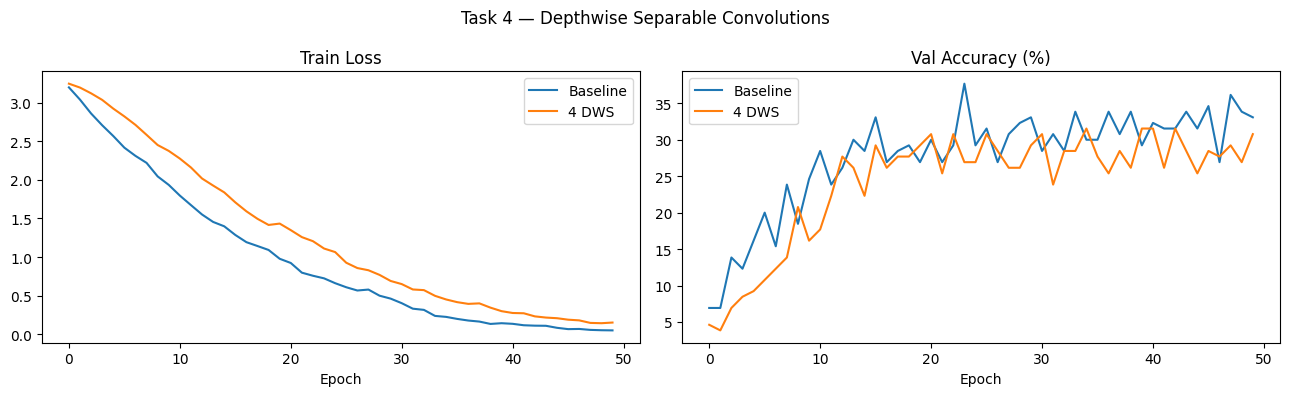

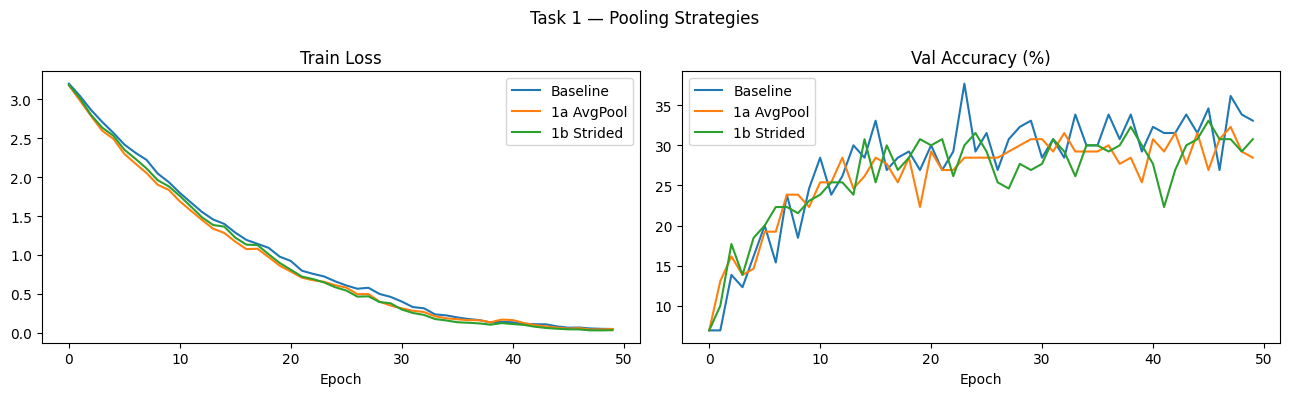

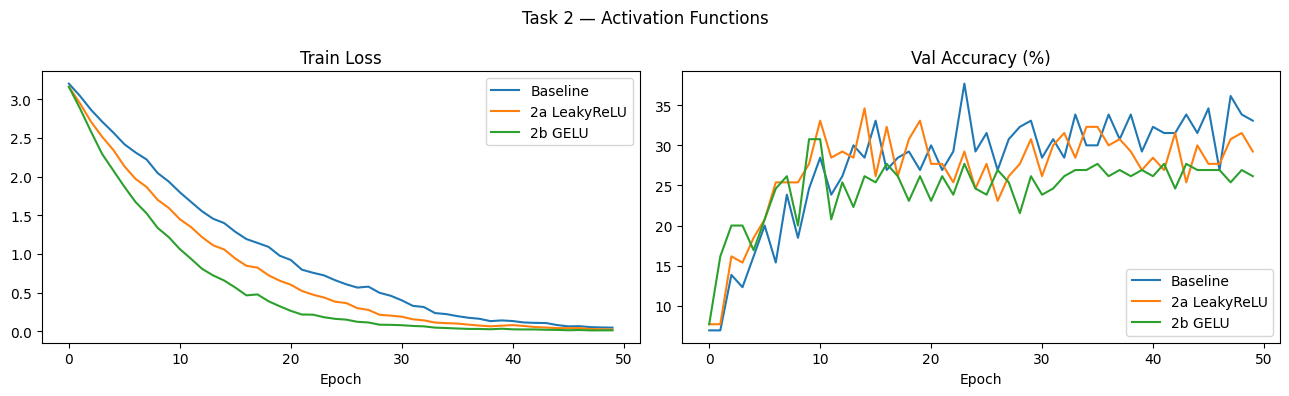

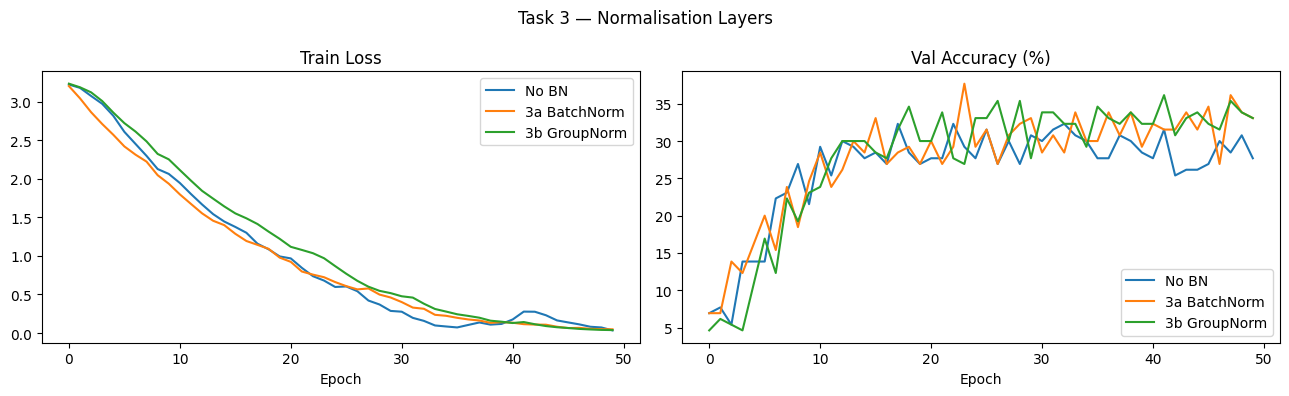

In [74]:
def measure_inference_time(model, loader, device, n_batches=20):
    model.eval().to(device)
    t0 = time.time()
    with torch.no_grad():
        for i, (data, _) in enumerate(loader):
            if i >= n_batches: break
            model(data.to(device))
    return (time.time() - t0) / n_batches


t_base = measure_inference_time(LeNetBase(), val_loader, device)
t_dws = measure_inference_time(model_dws, val_loader, device)
print(f'Baseline inference time / batch : {t_base * 1000:.1f} ms')
print(f'DWS      inference time / batch : {t_dws * 1000:.1f} ms')
print(f'Baseline parameters : {count_parameters(LeNetBase()):,}')
print(f'DWS      parameters : {count_parameters(model_dws):,}')
plot_curves({'Baseline': (losses_baseline, accs_baseline), '4 DWS': (losses_dws, accs_dws)},
            title='Task 4 — Depthwise Separable Convolutions')

# Extra: This has been added to provide a visual for the report.
# Task 1
plot_curves({'Baseline': (losses_baseline, accs_baseline),
             '1a AvgPool': (losses_avg, accs_avg),
             '1b Strided': (losses_strided, accs_strided)},
            title='Task 1 — Pooling Strategies')

# Task 2
plot_curves({'Baseline': (losses_baseline, accs_baseline),
             '2a LeakyReLU': (losses_lrelu, accs_lrelu),
             '2b GELU': (losses_gelu, accs_gelu)},
            title='Task 2 — Activation Functions')

# Task 3
plot_curves({'No BN': (losses_nobn, accs_nobn),
             '3a BatchNorm': (losses_bn, accs_bn),
             '3b GroupNorm': (losses_gn, accs_gn)},
            title='Task 3 — Normalisation Layers')


---
# Task 5 — Best Architecture

Design the best network you can within the following **hard constraints**:

| Constraint | Limit |
|---|---|
| Max parameters | **500,000** |
| Max epochs | **50** |
| Allowed layers | Lecture-covered only |
| Pre-trained weights | ❌ Not allowed |

Submit a `task5/` folder containing **`model.py`** (your `YourNet` class) and **`best_model.pth`** (saved weights).

## 5.1 — Augmentation Pipeline

In [62]:
START_seed()

t5_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),

    transforms.RandomHorizontalFlip(),

    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),

    transforms.RandomRotation(degrees=10),

    transforms.RandomGrayscale(p=0.1),

    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

t5_val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

t5_batch_size = 64
t5_train_set = CUB25Dataset(DATA_ROOT, split='train', transform=t5_train_transform)
t5_val_set = CUB25Dataset(DATA_ROOT, split='val', transform=t5_val_transform)
t5_train_loader = DataLoader(t5_train_set, batch_size=t5_batch_size, shuffle=True, num_workers=NUM_WORKERS)
t5_val_loader = DataLoader(t5_val_set, batch_size=t5_batch_size, shuffle=False, num_workers=NUM_WORKERS)
print(f'Task-5 train: {len(t5_train_set)} | val: {len(t5_val_set)}')

Task-5 train: 567 | val: 130


## 5.2 — Your Network

In [63]:
class YourNet(nn.Module):
    """
    5-block hybrid CNN: 2 standard Conv + 3 Depthwise Separable Conv.
    Trainable params: 437,593  (~87.5% of the 500k budget)

    Spatial flow (128x128 input):
      Block1: Conv(3->32,   k=3, p=1) + BN + ReLU + MaxPool(2)  ->  32x64x64
      Block2: Conv(32->64,  k=3, p=1) + BN + ReLU + MaxPool(2)  ->  64x32x32
      Block3: DWS(64->96)             + BN + ReLU + MaxPool(2)  ->  96x16x16
      Block4: DWS(96->128)            + BN + ReLU + MaxPool(2)  -> 128x8x8
      Block5: DWS(128->160)           + BN + ReLU               -> 160x8x8
      AdaptiveAvgPool(3,3)                                       -> 160x3x3
      Flatten -> Dropout(0.3)
      FC(1440->256) + BN1d + ReLU -> Dropout(0.3)
      FC(256->25)
    """

    def __init__(self, num_classes=25):
        super().__init__()

        # Block 1: Standart Conv
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)

        # Block 2: Standart Conv
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 3: Depthwise Separable (64 -> 96)
        self.dw3 = nn.Conv2d(64, 64, kernel_size=3, padding=1,
                             groups=64, bias=False)
        self.pw3 = nn.Conv2d(64, 96, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(96)

        # Block 4: Depthwise Separable (96 -> 128)
        self.dw4 = nn.Conv2d(96, 96, kernel_size=3, padding=1,
                             groups=96, bias=False)
        self.pw4 = nn.Conv2d(96, 128, kernel_size=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)

        # Block 5: Depthwise Separable (128 -> 160)
        self.dw5 = nn.Conv2d(128, 128, kernel_size=3, padding=1,
                             groups=128, bias=False)
        self.pw5 = nn.Conv2d(128, 160, kernel_size=1, bias=False)
        self.bn5 = nn.BatchNorm2d(160)

        #  Classifier head
        self.gap = nn.AdaptiveAvgPool2d((3, 3))
        self.drop = nn.Dropout(p=0.3)
        self.fc1 = nn.Linear(160 * 3 * 3, 256)
        self.bn_fc = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # Block 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)  # 128 -> 64

        # Block 2
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)  # 64 -> 32

        # Block 3 (DWS)
        x = F.relu(self.bn3(self.pw3(self.dw3(x))))
        x = F.max_pool2d(x, 2)  # 32 -> 16

        # Block 4 (DWS)
        x = F.relu(self.bn4(self.pw4(self.dw4(x))))
        x = F.max_pool2d(x, 2)  # 16 -> 8

        # Block 5 (DWS) — No pooling, Spatial knowledge preserved
        x = F.relu(self.bn5(self.pw5(self.dw5(x))))  # 8 -> 8

        # Global pooling + classifier
        x = self.gap(x)  # 8 -> 3
        x = x.view(x.size(0), -1)  # 1440
        x = self.drop(x)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.drop(x)
        return self.fc2(x)


START_seed()
your_model = YourNet()
n_params = count_parameters(your_model)
print(your_model)
print(f'\nParameters: {n_params:,}')
assert n_params <= MAX_PARAMS, f'❌ {n_params:,} params — exceeds {MAX_PARAMS:,} limit!'
print(f'✅ Within the {MAX_PARAMS:,} parameter budget.')


YourNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (dw3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
  (pw3): Conv2d(64, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (dw4): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=96, bias=False)
  (pw4): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (dw5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1

## 5.3 — Training

In [64]:
import os;

os.makedirs('task5', exist_ok=True)

START_seed()
your_model = YourNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(your_model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

your_model.to(device)
train_losses_t5, val_accs_t5 = [], []
best_acc_t5, best_epoch_t5 = 0.0, 0

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(your_model, device, t5_train_loader, optimizer, criterion, epoch)
    acc = evaluate(your_model, device, t5_val_loader, criterion)
    train_losses_t5.append(loss);
    val_accs_t5.append(acc)
    if acc > best_acc_t5:
        best_acc_t5, best_epoch_t5 = acc, epoch
        torch.save(your_model.state_dict(), 'task5/best_model.pth')
    scheduler.step()

print(f'\n✅ Best val: {best_acc_t5:.2f}% at epoch {best_epoch_t5}')
print(f'   Time: {time.time() - t0:.1f}s | Params: {count_parameters(your_model):,}')


  [Train] Epoch 01  Loss: 3.2444
  [Val]   Loss: 3.1324  Accuracy: 6/130 (4.62%)
  [Train] Epoch 02  Loss: 3.0056
  [Val]   Loss: 3.0505  Accuracy: 5/130 (3.85%)
  [Train] Epoch 03  Loss: 2.8957
  [Val]   Loss: 2.9588  Accuracy: 11/130 (8.46%)
  [Train] Epoch 04  Loss: 2.7095
  [Val]   Loss: 2.8470  Accuracy: 17/130 (13.08%)
  [Train] Epoch 05  Loss: 2.5971
  [Val]   Loss: 2.7034  Accuracy: 28/130 (21.54%)
  [Train] Epoch 06  Loss: 2.5377
  [Val]   Loss: 2.5566  Accuracy: 29/130 (22.31%)
  [Train] Epoch 07  Loss: 2.3667
  [Val]   Loss: 2.8408  Accuracy: 33/130 (25.38%)
  [Train] Epoch 08  Loss: 2.3242
  [Val]   Loss: 2.5654  Accuracy: 45/130 (34.62%)
  [Train] Epoch 09  Loss: 2.1910
  [Val]   Loss: 2.3995  Accuracy: 45/130 (34.62%)
  [Train] Epoch 10  Loss: 2.1679
  [Val]   Loss: 2.4384  Accuracy: 45/130 (34.62%)
  [Train] Epoch 11  Loss: 2.0597
  [Val]   Loss: 2.6071  Accuracy: 45/130 (34.62%)
  [Train] Epoch 12  Loss: 1.9572
  [Val]   Loss: 2.4946  Accuracy: 47/130 (36.15%)
  [Train]

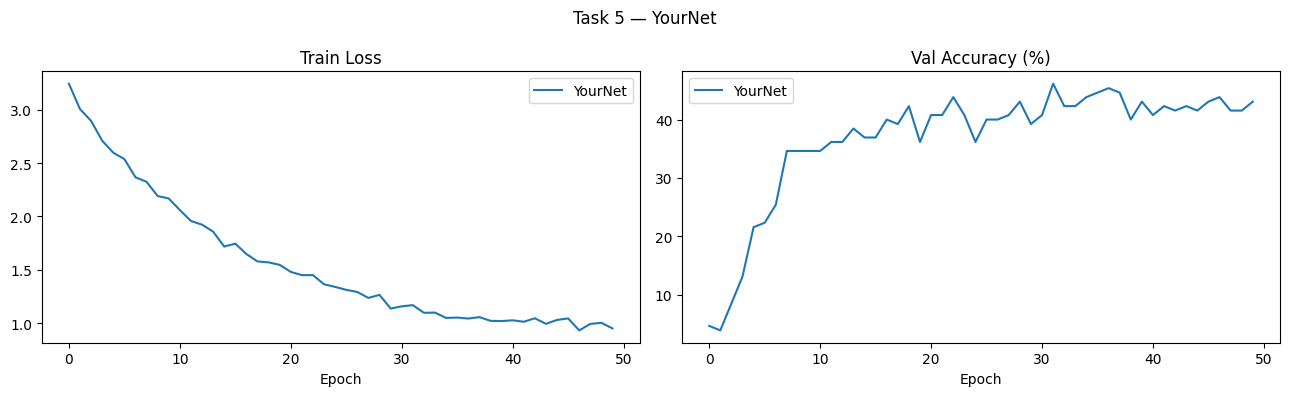

In [76]:
# Task 5
plot_curves({'YourNet': (train_losses_t5, val_accs_t5)},
            title='Task 5 — YourNet')

## 5.4 — Export model.py
Copy your `YourNet` class (and any helper classes) into `task5/model.py`.
It must be importable as `from model import YourNet` without any other files.

In [66]:
template = '''
import torch
import torch.nn as nn
import torch.nn.functional as F

class YourNet(nn.Module):
    def __init__(self, num_classes=25):
        super().__init__()

        # Block 1: Standart Conv
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)

        # Block 2: Standart Conv
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 3: Depthwise Separable (64 -> 96)
        self.dw3 = nn.Conv2d(64, 64, kernel_size=3, padding=1,
                             groups=64, bias=False)
        self.pw3 = nn.Conv2d(64, 96, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(96)

        # Block 4: Depthwise Separable (96 -> 128)
        self.dw4 = nn.Conv2d(96, 96, kernel_size=3, padding=1,
                             groups=96, bias=False)
        self.pw4 = nn.Conv2d(96, 128, kernel_size=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)

        # Block 5: Depthwise Separable (128 -> 160)
        self.dw5 = nn.Conv2d(128, 128, kernel_size=3, padding=1,
                             groups=128, bias=False)
        self.pw5 = nn.Conv2d(128, 160, kernel_size=1, bias=False)
        self.bn5 = nn.BatchNorm2d(160)

        #  Classifier head
        self.gap = nn.AdaptiveAvgPool2d((3, 3))
        self.drop = nn.Dropout(p=0.3)
        self.fc1 = nn.Linear(160 * 3 * 3, 256)
        self.bn_fc = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # Block 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)  # 128 -> 64

        # Block 2
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)  # 64 -> 32

        # Block 3 (DWS)
        x = F.relu(self.bn3(self.pw3(self.dw3(x))))
        x = F.max_pool2d(x, 2)  # 32 -> 16

        # Block 4 (DWS)
        x = F.relu(self.bn4(self.pw4(self.dw4(x))))
        x = F.max_pool2d(x, 2)  # 16 -> 8

        # Block 5 (DWS) — No pooling, Spatial knowledge preserved
        x = F.relu(self.bn5(self.pw5(self.dw5(x))))  # 8 -> 8

        # Global pooling + classifier
        x = self.gap(x)  # 8 -> 3
        x = x.view(x.size(0), -1)  # 1440
        x = self.drop(x)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.drop(x)
        return self.fc2(x)
'''

os.makedirs('task5', exist_ok=True)
with open('task5/model.py', 'w') as f:
    f.write(template.strip() + '\n')
print('Template written to task5/model.py — fill it in with your implementation.')


Template written to task5/model.py — fill it in with your implementation.
